# GenMol - Basics

## Setup
This notebook assumes that the NIM is running! Ports for the NIMs:
- AlphaFold2: 8081
- MolMIM: 8082
- **GenMOL: 8083**
- diffdock : 8084


In [1]:
!pip install safe-mol datamol pandas numpy rdkit matplotlib 2>/dev/null | tail -n 1

In [2]:
#!pip install safe-mol datamol 2>/dev/null | tail -n 1

In [3]:
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.utils import Utils

from rdkit import Chem
from rdkit.Chem import Draw

# SAFE <> SMILES conversion
import safe as sf
import datamol as dm

import pandas as pd

GENMOL_HOST = 'http://127.0.0.1:8083'
gm = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")


## Test NIM availability

In [4]:
!curl {GENMOL_HOST}/v1/health/ready

true

## Define Seeds and used Seed for generation

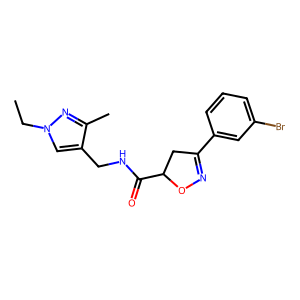

In [5]:
#Seed 1
m1 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m1_name = "BCS-CE65417"

seed_mol_m1  = dm.to_mol(m1)
display(dm.to_image(seed_mol_m1))

In [6]:
# define the seed to be used in the notebook
m_seq = m1
seed_mol = seed_mol_m1

## check SAFE conversion & Reconstruction

In [7]:
safe_str = sf.encode(seed_mol)
print(f"SMILES: {m_seq}")
print(f"SAFE:   {safe_str}\n represented using {len(safe_str.split('.'))} fragments")

SMILES: CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1
SAFE:   C16CC(c2cccc(Br)c2)=NO1.n17cc8c(C)n1.C46=O.CC7.C58.N45
 represented using 6 fragments


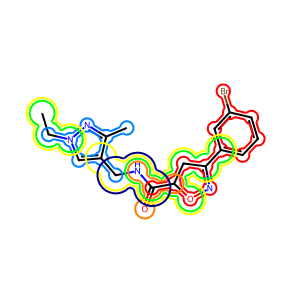

In [8]:
sf.to_image(safe_str)

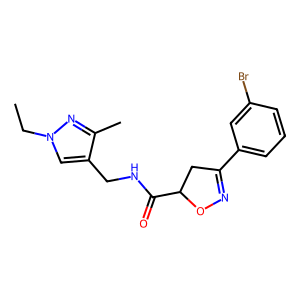

In [9]:
testreconstructed = dm.to_mol(safe_str)
display(dm.to_image(testreconstructed))

# Base Generation

Just a test generation to see if model is woring... basically the "de novo" way to generate molecules

In [10]:
result = gm.produce([m_seq], 10)

In [11]:
print(result[0])
print(m_seq)

CNc1cc(OC)c(N[C@@H](C)Cc2ncon2)cn1
CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1


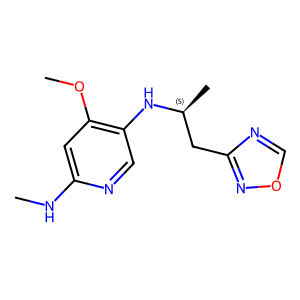

In [12]:
res_mol  = dm.to_mol(result[0])
display(dm.to_image(res_mol))

# Motif-Extension or Scaffold-Decoration

input is single fragment

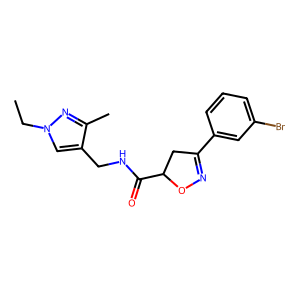

In [13]:
#draw original mol
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

### Example 1: first fragment

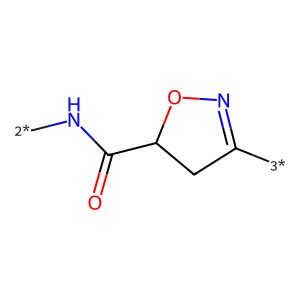

In [14]:
# add wildcard to a fragment
smiles_masked_1 = '[2*]NC(=O)C1CC(=NO1)[3*]'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [17]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules_e1 = gm.inference(smiles = safe_to_gen + '.[*{8-20}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e1)

58

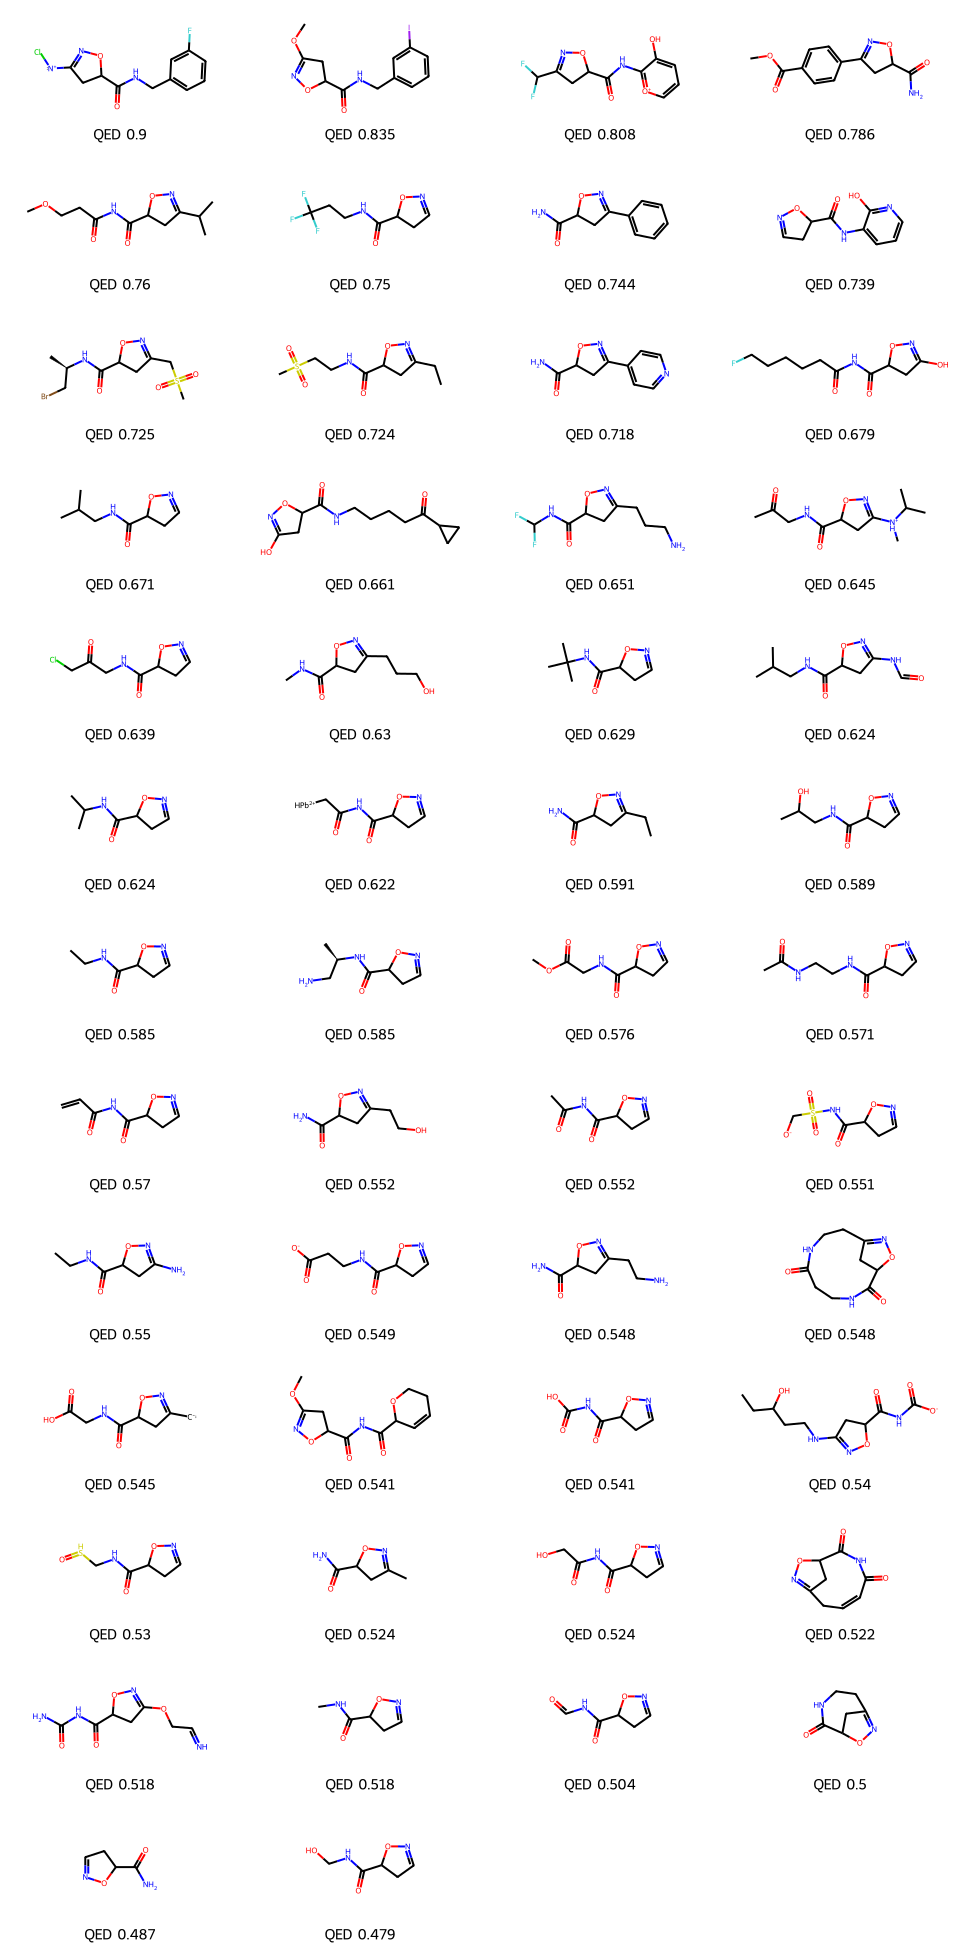

In [18]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e1]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e1])

In [19]:
# Create a DataFrame + add results
df_results = pd.DataFrame(molecules_e1)

## Example 2: second fragment

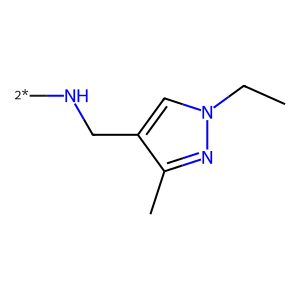

In [21]:
# add wildcard to a fragment
smiles_masked_2 = 'CC1=NN(CC)C=C1CN[2*]' 
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [27]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_2)
safe_to_gen
molecules_e2 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e2)

34

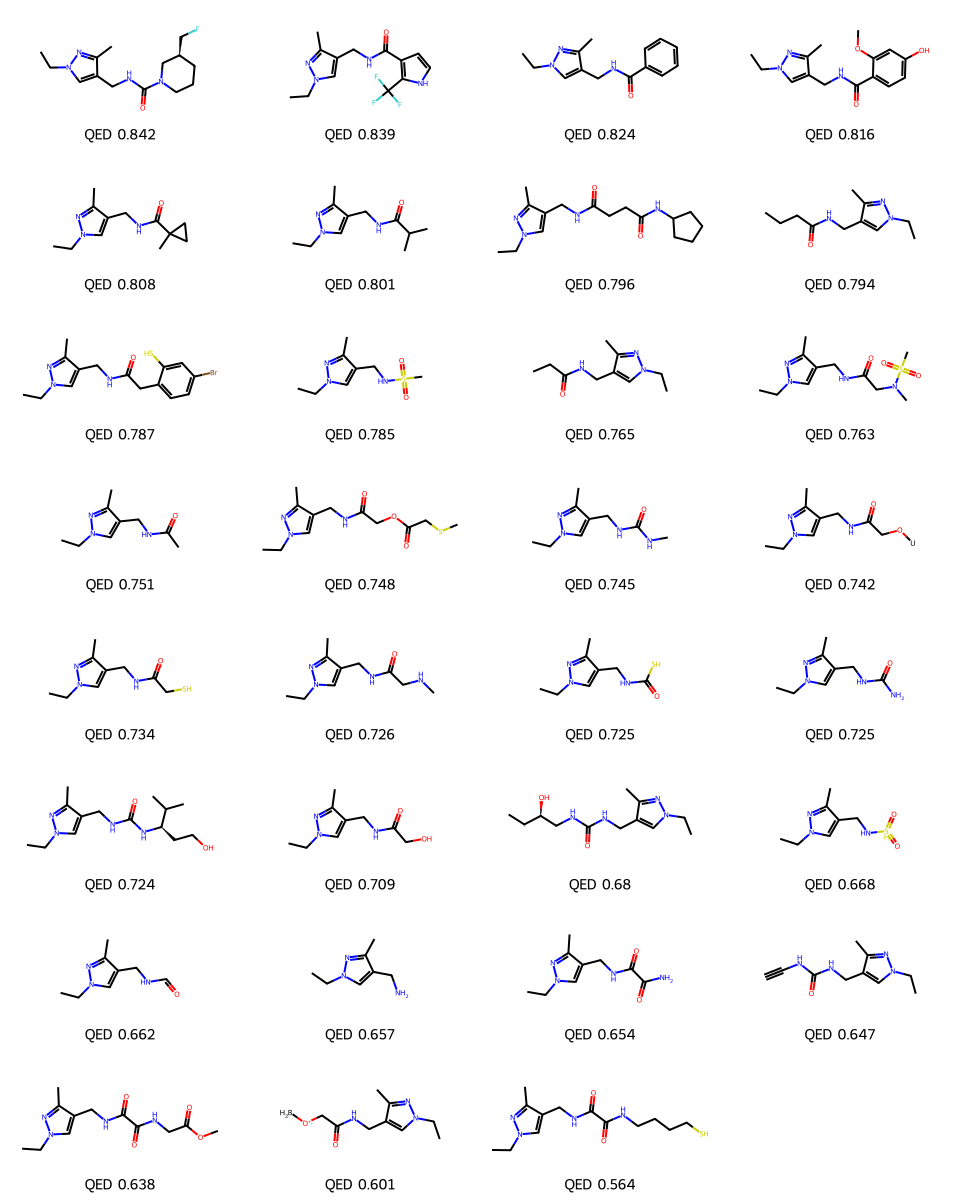

In [28]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e2]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e2])

In [29]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e2)], ignore_index=True)

In [30]:
len(df_results)

123

## Example 3: third fragment

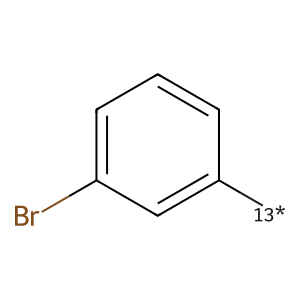

In [33]:
# add wildcard to a fragment
smiles_masked_3 = '[13*](C1C=C(Br)C=CC=1)' 
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [34]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_3)
safe_to_gen
molecules_e3 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e3)

7

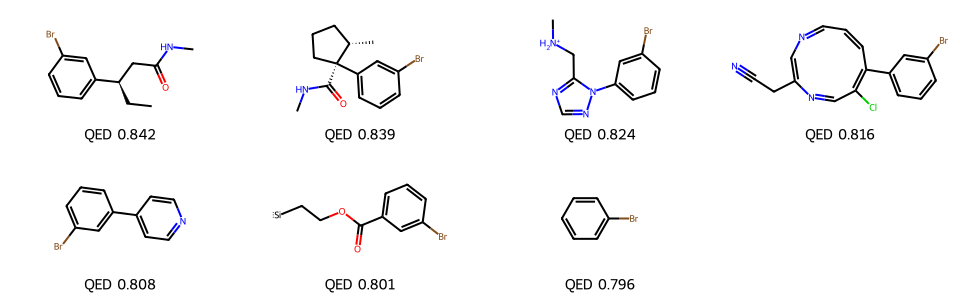

In [35]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e3]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e3])

In [36]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e3)], ignore_index=True)

In [37]:
len(df_results)

130

# Fragment based generation 
(Linker generation / Scaffold morphing)

## Mask at the end

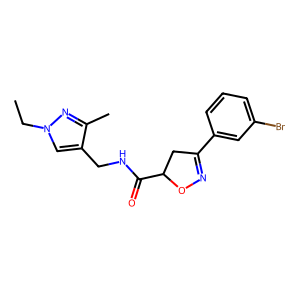

In [38]:
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

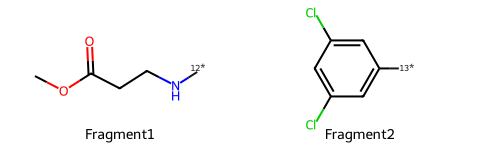

In [39]:
frag1, frag2 = 'COC(=O)CCN[12*]', '[13*](c2cc(Cl)cc(Cl)c2)' #'[11*]C1(CC#N)CN(S(=O)(=O)CC)C1', '[13*]c1ncnc2[nH]ccc12' #  'COC(=O)CCNC[11*]

Draw.MolsToGridImage([Chem.MolFromSmiles(frag1), Chem.MolFromSmiles(frag2)], 
                      molsPerRow=2, subImgSize=(240, 150), legends=['Fragment1', 'Fragment2'])

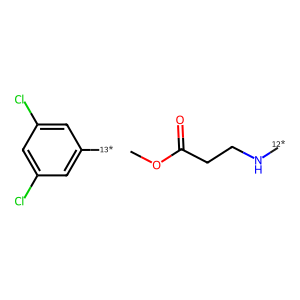

In [42]:
smiles_joint = '.'.join([frag1, frag2])
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [43]:
# mask at the end
input_text = Utils.smiles2safe(smiles_joint) + '.[*{5-20}]'
input_text

'c14cc(Cl)cc(Cl)c1.C5(=O)CC6.CO5.N36.[*{5-20}]'

In [44]:
molecules_e4 = gm.inference(smiles=input_text, temperature =2.0, noise =1.0, num_molecules=1000, step_size=1)
len(molecules)

82

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


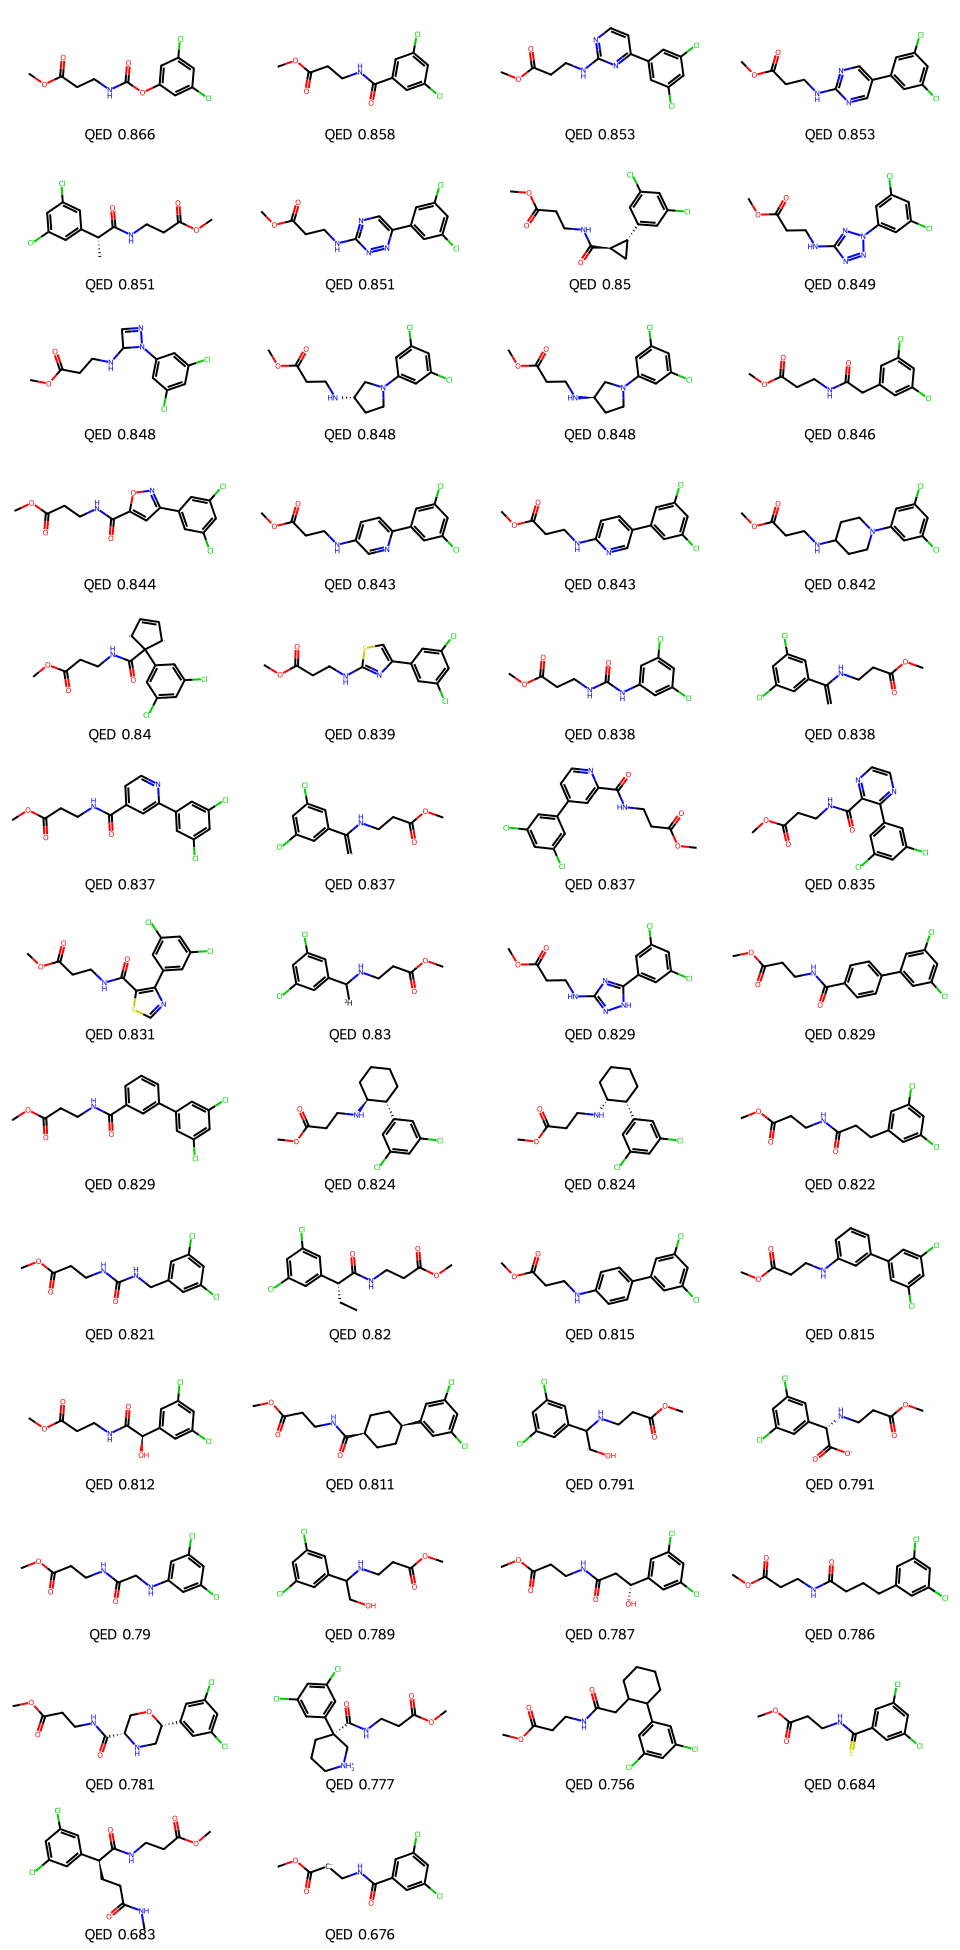

In [45]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e4]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e4])

In [46]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e4)], ignore_index=True)
print(len(df_results))
df_results.head()

212


,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835
2,O=C(Nc1[o+]cccc1O)C1CC(C(F)F)=NO1,0.808
3,COC(=O)c1ccc(C2=NOC(C(N)=O)C2)cc1,0.786
4,COCCC(=O)NC(=O)C1CC(C(C)C)=NO1,0.760


## Mask in the center

COC(=O)CCN[12*].[13*](c2cc(Cl)cc(Cl)c2)


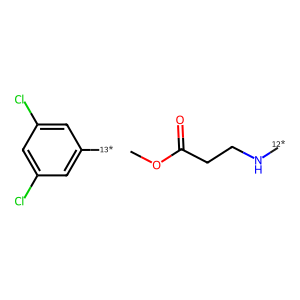

In [47]:
smiles_joint = '.'.join([frag1, frag2])
print(smiles_joint)
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [48]:
#what sub-fragments are in frag1 
text_frag1 = Utils.smiles2safe(frag1).split('.')
text_frag1

['C2(=O)CC3', 'CO2', 'N13']

In [49]:
#what sub-fragments are in frag2
text_frag2 = Utils.smiles2safe(frag2).split('.')
text_frag2

['c13cc(Cl)cc(Cl)c1']

In [50]:
#what sub-fragments are in the full mol?
input_text = Utils.smiles2safe(smiles_joint).split('.')
input_text

['c14cc(Cl)cc(Cl)c1', 'C5(=O)CC6', 'CO5', 'N36']

In [51]:
input_text[1:]

['C5(=O)CC6', 'CO5', 'N36']

In [53]:
# select where to set mask
input_w_mask = '.'.join(input_text[:1]) + '.[*{5-18}].' + '.'.join(input_text[1:])
input_w_mask

'c14cc(Cl)cc(Cl)c1.[*{5-18}].C5(=O)CC6.CO5.N36'

In [55]:
molecules_e5 = gm.inference(smiles = input_w_mask, temperature = 2.0, noise = 1.0, num_molecules=100)
len(molecules)

35

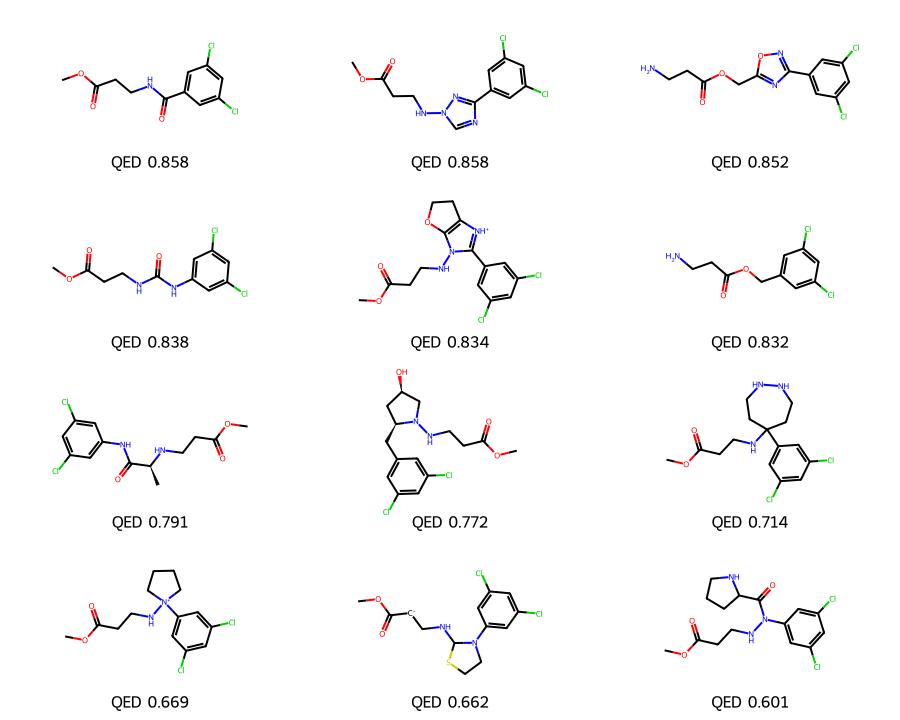

In [56]:
Draw.MolsToGridImage([Chem.MolFromSmiles(_['smiles']) for _ in molecules_e5[:12]], 
                      molsPerRow=3, subImgSize=(300, 180), legends=['QED ' + str(_['score']) for _ in molecules_e5[:12]])

In [57]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e5)], ignore_index=True)
print(len(df_results))
df_results.head()

236


,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835
2,O=C(Nc1[o+]cccc1O)C1CC(C(F)F)=NO1,0.808
3,COC(=O)c1ccc(C2=NOC(C(N)=O)C2)cc1,0.786
4,COCCC(=O)NC(=O)C1CC(C(C)C)=NO1,0.760


In [58]:
#df_results.to_csv("../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv", index=False)

# Superstructure Generation

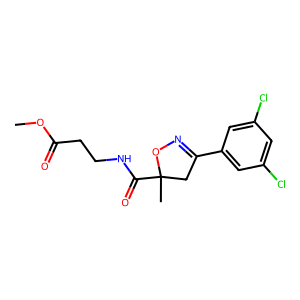

In [67]:
smiles = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles))

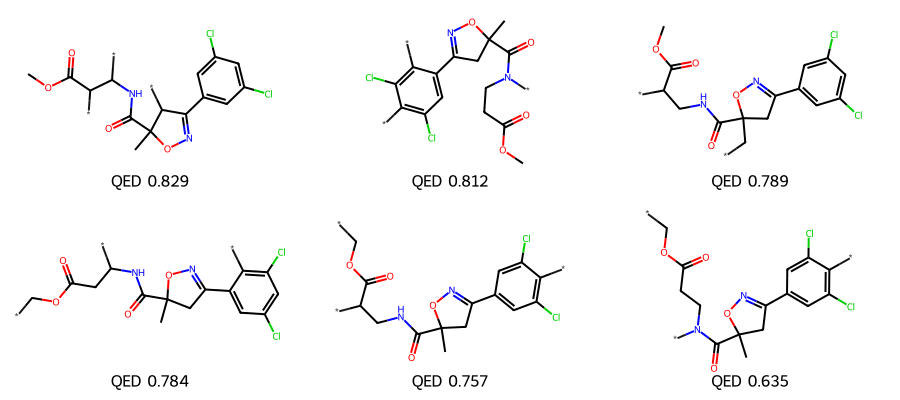

In [68]:
cores = Utils.attachable_points(smiles)[:6]
ms = [Chem.MolFromSmiles(_) for _ in cores]
Draw.MolsToGridImage(ms, molsPerRow=3, subImgSize=(300, 200), legends=['QED ' + str(_['score']) for _ in molecules])

In [69]:
safes = [Utils.smiles2safe(_) for _ in cores]
molecules = [gm.inference(smiles = _ + '.[*{15-15}]', num_molecules = 10, temperature = 1.5, noise = 1.0)[0] for _ in safes]

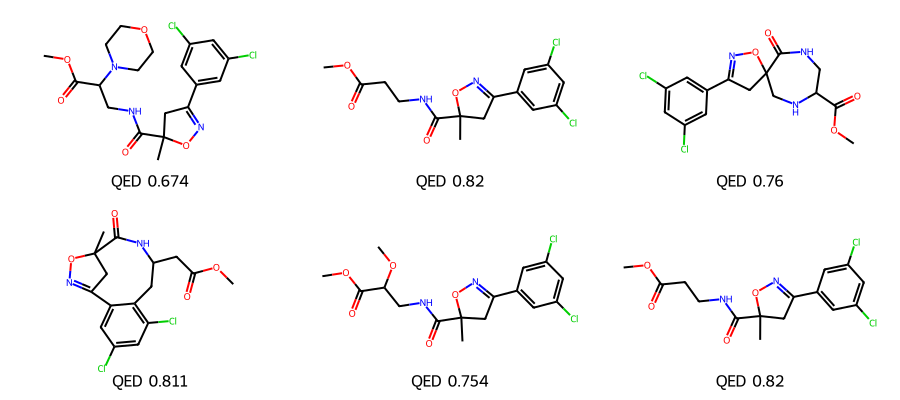

In [70]:
smiless = [_['smiles'] for _ in molecules]
ms = [Chem.MolFromSmiles(_) for _ in smiless]
Draw.MolsToGridImage(ms, molsPerRow=3, subImgSize=(300, 200), legends=['QED ' + str(_['score']) for _ in molecules])